In [1]:
# CONFIGS
TRAIN_TEST_SPLIT    = 0.85
AUG_ROTATION_DEG    = 15
AUG_TRANSLATION_PIX = 20

N_DATALOADER_WORKERS = 12

BATCH_SIZE = 128
N_EPOCHS = 20

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
"""
This code is deactivated because training is now focused on cifar10 (pre-split) instead of imagenet

# Makes a train/test split with hardlinks
base = Path('./datasets/imagenet-256/raw/')

(base.parent/'train').mkdir()
(base.parent/'valid').mkdir()

# Bucket by label
buckets: dict[str, list[Path]] = {}
for file in base.rglob('*.*'):
    label = file.as_posix().rsplit('/', 2)[1]
    buckets.setdefault(label, []).append(file)

for label in buckets:
    (base.parent/'train'/label).mkdir()
    (base.parent/'valid'/label).mkdir()
    num_train = round(len(buckets[label]) * TRAIN_TEST_SPLIT)
    for i, path in enumerate(buckets[label]):
        if i < num_train:
            (base.parent/'train'/label/path.name).hardlink_to(path)
        else:
            (base.parent/'valid'/label/path.name).hardlink_to(path)

assert TRAIN_TEST_SPLIT == 0.85, "Split is out of date"
"""

assert True

In [4]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

In [5]:
from PIL import Image
import numpy as np

In [6]:
from pathlib import Path
from random import randint

import typing

In [7]:
# Modified Linear from PyTorch's 2.14.0 linear.py
class ProjectionLinear(nn.Module):
    __constants__ = ["in_features", "out_features"]
    in_features: int
    out_features: int

    def __init__(
        self,
        in_features: int,
        out_features: int,
        bias: bool = True,
        device=None,
        dtype=None,
    ) -> None:
        factory_kwargs = {"device": device, "dtype": dtype}
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weights_out = nn.parameter.Parameter(
            torch.empty((out_features, 1), **factory_kwargs)
        )
        self.weights_in = nn.parameter.Parameter(
            torch.empty((1, in_features), **factory_kwargs)
        )
        if bias:
            self.bias = nn.parameter.Parameter(torch.empty(out_features, **factory_kwargs))
        else:
            self.register_parameter("bias", None)
        self.reset_parameters()

    def proj_weights(self) -> torch.Tensor:
        return self.weights_out @ self.weights_in

    def reset_parameters(self) -> None:
        """
        Resets parameters based on their initialization used in ``__init__``.
        """
        # Setting a=sqrt(5) in kaiming_uniform is the same as initializing with
        # uniform(-1/sqrt(in_features), 1/sqrt(in_features)). For details, see
        # https://github.com/pytorch/pytorch/issues/57109
        nn.init.kaiming_uniform_(self.weights_in, a=math.sqrt(5))
        nn.init.kaiming_uniform_(self.weights_out, a=math.sqrt(5))
        if self.bias is not None:
            fan_in, _ = nn.init._calculate_fan_in_and_fan_out(self.proj_weights())
            bound = 1 / math.sqrt(fan_in) if fan_in > 0 else 0
            nn.init.uniform_(self.bias, -bound, bound)

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        """
        Runs the forward pass.
        """
        return nn.functional.linear(input, self.proj_weights(), self.bias)

    def extra_repr(self) -> str:
        """
        Return the extra representation of the module.
        """
        return f"in_features={self.in_features}, out_features={self.out_features}, bias={self.bias is not None}"

In [8]:
class SimpleNet(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.Flatten(),
            ProjectionLinear(3*32*32, 512),
            nn.ReLU(),
            ProjectionLinear(512, 128),
            nn.ReLU(),
            ProjectionLinear(128, 10)
        )

In [9]:
class ImageDataset(Dataset):
    def __init__(
        self,
        path: str | Path,
        image_transforms: typing.Callable | None = None,
        fmt: str = "RGB"
    ):
        """
        Expects a set of files in path/<label>/<sample>
        Assumes all files matching '*.*' recursively in the directory are images

        Args:
          path: path to the base directory as documented above
          image_transforms: callable taking input as type PIL.Image and applying a transformation, returning the new image, default=None
          fmt: PIL image format to load images as, default="RGB"
        """

        if isinstance(path, str):
            path = Path(path)

        self.samples: list[tuple[str, Path]] = []
        labels: set[str] = set()

        # Build sample map
        for file in path.rglob('*.*'):
            label = file.as_posix().rsplit('/', 2)[1]
            
            self.samples.append((label, file))
            labels.add(label)

        self.labels = list(labels)

        # Build label to one-hot map
        self.one_hot_index: dict[str, int] = {}
        i = 0
        for l in self.labels:
            self.one_hot_index[l] = i
            i += 1

        self.image_transforms = image_transforms
        self.fmt = fmt

    def __getitem__(self, idx):
        """
        Returns input_tensor, target_tensor at the given index
        """
        label, file = self.samples[idx]

        # Image -> transform (optional) -> read-only np array -> normalize -> copy into tensor
        im = Image.open(file).convert(self.fmt)

        if self.image_transforms is not None:
            im = self.image_transforms(im)
        
        input_tensor = torch.tensor(np.asarray(im) / 255, dtype=torch.float32).permute(2, 0, 1) # Permute to CxHxW

        # Target tensor encoding
        target_tensor = torch.zeros(len(self.labels), dtype=torch.float32)
        target_tensor[self.one_hot_index[label]] = 1

        return input_tensor, target_tensor

    def __len__(self):
        return len(self.samples)

In [10]:
def augment_image(im: Image.Image) -> Image.Image:
    im = im.rotate(randint(-AUG_ROTATION_DEG, AUG_ROTATION_DEG), translate=(randint(-AUG_TRANSLATION_PIX, AUG_TRANSLATION_PIX), randint(-AUG_TRANSLATION_PIX, AUG_TRANSLATION_PIX)))
    return im

t_dataset = ImageDataset('./datasets/cifar10/train', image_transforms=augment_image)
v_dataset = ImageDataset('./datasets/cifar10/valid', image_transforms=augment_image)

In [11]:
t_loader = DataLoader(
    t_dataset,
    batch_size=BATCH_SIZE,
    pin_memory=True,
    shuffle=True,
    num_workers=N_DATALOADER_WORKERS
)
v_loader = DataLoader(
    v_dataset,
    batch_size=BATCH_SIZE,
    pin_memory=True,
    shuffle=False,
    num_workers=N_DATALOADER_WORKERS
)

In [12]:
from ember.metric import State, ExpAvgMetric, Metric
from ember.callback import Callback

class TrainAccuracyMetric(ExpAvgMetric):
    state = State.TRAIN
    do_reporting = True
    name = "train acc"

    def step(self):
        accuracy = (self.learner.preds.argmax(dim=1) == self.learner.y.argmax(dim=1))
        accuracy = accuracy.sum() / self.learner.x.shape[0]
        self.avg.step(accuracy.item() * 100)

class ValidAccuracyCallback(Callback):
    def before_valid(self):
        self.learner.valid_accuracy = [0, 0]
    def after_batch(self):
        if self.learner.state == State.VALID:
            correct = (self.learner.preds.argmax(dim=1) == self.learner.y.argmax(dim=1)).sum().item()
            self.learner.valid_accuracy[0] += correct
            self.learner.valid_accuracy[1] += len(self.learner.x)

class ValidAccuracyMetric(Metric):
    state = State.VALID
    do_reporting = True
    name = "valid acc"

    @property
    def value(self):
        correct, total = self.learner.valid_accuracy
        return float(correct) / float(total) * 100

In [13]:
# Training!
from ember import Learner
from ember.callback import *
from ember.metric import *

from ember.learner import device

model = SimpleNet()
optim = torch.optim.AdamW(model.parameters())
learner = Learner(model, optim, t_loader, v_loader, loss_fn=nn.CrossEntropyLoss(), clip_grads=1,
                 metrics = [LRMetric(), TrainLossMetric(), ValidLossMetric(), TrainAccuracyMetric(), ValidAccuracyMetric()],
                 cbs     = [SaveBestCallback("./exports/cifar10/autosave"), StatusCallback(), ValidAccuracyCallback()]
)

print(f"Training on {device}")

learner.fit_one_cycle(N_EPOCHS, max_lr=4e-3)

Training on cuda


epoch,train loss,valid loss,train acc,valid acc,time
0,2.2860699,2.2894326,11.50761,11.37000,00:02
1,2.2013932,2.2010236,17.81059,17.46000,00:04
2,2.1499410,2.1420250,19.09951,17.70000,00:06
3,2.1390292,2.1312903,18.06390,18.48000,00:08
4,2.1308398,2.1329629,17.12948,17.65000,00:10
5,2.1335265,2.1366051,19.10963,18.64000,00:13
6,2.1280606,2.1399834,17.94674,17.87000,00:15
7,2.1360883,2.1278651,17.70777,18.69000,00:17
8,2.1284041,2.1274909,17.86286,17.59000,00:19
9,2.1306211,2.1270415,18.56677,18.58000,00:21


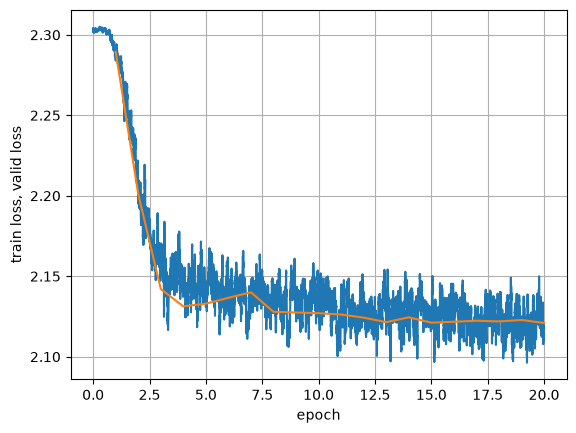

In [14]:
learner.recorder.plot("train loss", "valid loss")

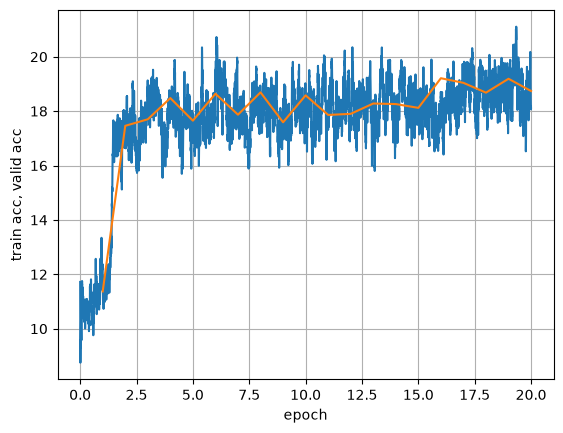

In [15]:
learner.recorder.plot("train acc", "valid acc")